# Actividad: correlación y regresión

Matemáticas para la Computación. Arturo Zabdi Reyes Pérez.

Se estudia el precio por noche de los anuncios de Airbnb en la Ciudad de México con el corte del 23 de septiembre de 2026 de Inside Airbnb. El propósito del modelo es **explicativo**: se busca cuantificar la asociación entre el precio y un conjunto reducido de atributos, cada uno con los demás fijos, y no construir un predictor. Por esa razón se exige que los predictores tengan baja correlación entre sí, se revisan los residuos para validar la inferencia y se reportan errores estándar robustos.

Pasos: (1) correlación entre las variables independientes; (2) selección de tres variables poco correlacionadas; (3) gráficas de dispersión; (4) especificación de un modelo lineal; (5) residuos y ajuste.

In [1]:
import itertools
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from scipy import stats

# Corte de septiembre de 2026 de Inside Airbnb, el del proyecto 2
ARCHIVO = Path("../../proyecto2/data/2026-09-23/listings.csv.gz")
RUTA_FIGURAS = Path("figuras")

# Rango de precio por noche considerado plausible
PRECIO_MIN, PRECIO_MAX = 100, 50_000

# Meridiano y paralelo de referencia: el Angel de la Independencia
LON_REFERENCIA, LAT_REFERENCIA = -99.1677, 19.4270
KM_POR_GRADO = 111.32

# Dos predictores se consideran poco correlacionados si |rho| < UMBRAL
UMBRAL = 0.3

# Semilla de la particion entrenamiento / prueba
SEMILLA = 13

VERDE, MORADO = "#0f766e", "#7c3aed"
plt.rcParams.update({"figure.dpi": 110, "font.size": 9,
                     "axes.spines.top": False, "axes.spines.right": False})
RUTA_FIGURAS.mkdir(exist_ok=True)

## Datos

Se consideran trece variables candidatas: características físicas del inmueble (recámaras, camas, baños, número de amenidades), ubicación en coordenadas geográficas (latitud y longitud), tipo de alojamiento (indicadora de alojamiento entero frente a cuarto), y atributos del anfitrión y de la operación del anuncio. El número de baños se extrae de `bathrooms_text`, ya que la columna numérica viene vacía en este corte. Se conservan los precios entre 100 y 50,000 pesos por noche.

In [2]:
crudo = pd.read_csv(ARCHIVO, low_memory=False)
precio = crudo["price"].str.replace(r"[$,]", "", regex=True).astype(float)
texto_bano = crudo["bathrooms_text"].str.lower()
banos = texto_bano.str.extract(r"(\d+(?:\.\d+)?)")[0].astype(float)
banos = banos.mask(banos.isna() & texto_bano.str.contains("half"), 0.5)

anuncios = pd.DataFrame({
    "precio": precio,
    "recamaras": crudo["bedrooms"],
    "camas": crudo["beds"],
    "banos": banos,
    "amenidades": crudo["amenities"].map(lambda s: len(json.loads(s))),
    "latitud": crudo["latitude"],
    "longitud": crudo["longitude"],
    "entero": (crudo["room_type"] == "Entire home/apt").astype(int),
    "superanfitrion": (crudo["host_is_superhost"] == "t").astype(int),
    "resenas": crudo["number_of_reviews"],
    "disponibilidad": crudo["availability_365"],
    "noches_min": crudo["minimum_nights"],
    "anuncios_anfitrion": crudo["host_listings_count"],
    "antig_anfitrion": crudo["hosts_time_as_host_years"],
    # Fuera de las candidatas: se usan en el diagnostico
    "compartido": texto_bano.str.contains("shared", na=False).astype(int),
    "host_id": crudo["host_id"],
})
CANDIDATAS = ["recamaras", "camas", "banos", "amenidades", "latitud",
              "longitud", "entero", "superanfitrion", "resenas",
              "disponibilidad", "noches_min", "anuncios_anfitrion",
              "antig_anfitrion"]

con_precio = anuncios[anuncios["precio"].between(PRECIO_MIN,
                                                 PRECIO_MAX)].copy()
con_precio["log_precio"] = np.log(con_precio["precio"])
print(f"anuncios en el corte: {len(anuncios):,}")
print(f"con precio entre {PRECIO_MIN} y {PRECIO_MAX:,} pesos: "
      f"{len(con_precio):,}")
display(con_precio[CANDIDATAS].isna().mean().mul(100).round(1)
        .rename("% faltante").to_frame().T)

anuncios en el corte: 30,468
con precio entre 100 y 50,000 pesos: 28,323


,recamaras,camas,banos,amenidades,latitud,longitud,entero,superanfitrion,resenas,disponibilidad,noches_min,anuncios_anfitrion,antig_anfitrion
% faltante,0.1,1.4,0.1,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


## Paso 1: correlación entre las variables independientes

Se emplea el coeficiente de Spearman, que no se ve afectado por las colas largas de variables como el número de reseñas o de anuncios por anfitrión.

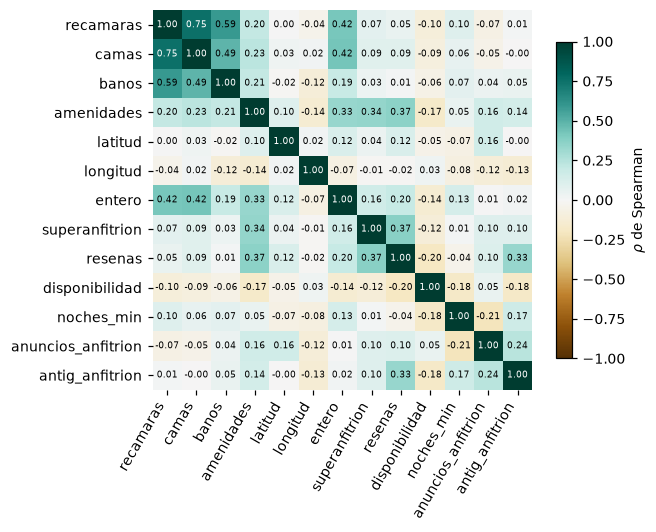

In [3]:
spearman = con_precio[CANDIDATAS].corr(method="spearman")

fig, eje = plt.subplots(figsize=(6.0, 5.0))
imagen = eje.imshow(spearman, cmap="BrBG", vmin=-1, vmax=1)
eje.set_xticks(range(len(CANDIDATAS)), CANDIDATAS, rotation=60,
               ha="right")
eje.set_yticks(range(len(CANDIDATAS)), CANDIDATAS)
for i, j in itertools.product(range(len(CANDIDATAS)), repeat=2):
    valor = spearman.iloc[i, j]
    eje.text(j, i, f"{valor:.2f}", ha="center", va="center", fontsize=6,
             color="white" if abs(valor) > 0.6 else "black")
eje.spines[:].set_visible(False)
fig.colorbar(imagen, ax=eje, shrink=0.8, label=r"$\rho$ de Spearman")
fig.tight_layout()
fig.savefig(RUTA_FIGURAS / "Correlacion.pdf", bbox_inches="tight")
plt.show()

Recámaras, camas y baños forman un bloque de alta correlación (0.49 a 0.75), pues las tres miden el tamaño del inmueble. Fuera de ese bloque hay correlaciones moderadas, de 0.33 a 0.42: el alojamiento entero con recámaras, camas y amenidades, y las amenidades, las reseñas y la condición de superanfitrión entre sí, que en conjunto describen anuncios más consolidados. El resto de los pares presenta correlaciones bajas.

## Paso 2: selección de las tres variables

Se evalúan todas las ternas posibles. Una terna es admisible si todos sus pares cumplen $|\rho| < 0.3$; entre las admisibles se elige la de mayor asociación conjunta con $\log(\text{precio})$, medida como la suma de los $|\rho|$ individuales.

In [4]:
con_y = (con_precio[CANDIDATAS]
         .corrwith(con_precio["log_precio"], method="spearman"))
display(con_y.round(3).sort_values(key=abs, ascending=False)
        .rename("rho con log(precio)").to_frame())

ternas = []
for terna in itertools.combinations(CANDIDATAS, 3):
    peor = max(abs(spearman.loc[a, b])
               for a, b in itertools.combinations(terna, 2))
    if peor < UMBRAL:
        ternas.append({"terna": ", ".join(terna),
                       "max |rho| entre ellas": round(peor, 3),
                       "suma |rho| con y": round(con_y[list(terna)]
                                                 .abs().sum(), 3)})
ternas = (pd.DataFrame(ternas)
          .sort_values("suma |rho| con y", ascending=False)
          .reset_index(drop=True))
total = len(list(itertools.combinations(CANDIDATAS, 3)))
print(f"ternas admisibles: {len(ternas)} de {total}")
display(ternas.head(6))

,rho con log(precio)
entero,0.525
recamaras,0.493
camas,0.454
banos,0.387
amenidades,0.359
longitud,-0.231
superanfitrion,0.130
anuncios_anfitrion,0.112
latitud,0.091
disponibilidad,-0.063


ternas admisibles: 190 de 286


,terna,max |rho| entre ellas,suma |rho| con y
0,"banos, longitud, entero",0.191,1.143
1,"recamaras, amenidades, longitud",0.205,1.084
2,"camas, amenidades, longitud",0.232,1.045
3,"banos, entero, superanfitrion",0.191,1.042
4,"banos, entero, anuncios_anfitrion",0.191,1.023
5,"banos, latitud, entero",0.191,1.003


La terna seleccionada es **baños, longitud y alojamiento entero**, con una correlación máxima de 0.19 entre sus pares. Las tres variables representan dimensiones distintas: tamaño, ubicación y tipo de alojamiento. Para la interpretación, la longitud se expresa como distancia en kilómetros al este del meridiano del Ángel de la Independencia; al ser una transformación lineal, no altera ninguna correlación.

In [5]:
PREDICTORES = ["banos", "longitud", "entero"]

muestra = con_precio.dropna(subset=PREDICTORES).copy()
# Posicion este-oeste en km respecto al meridiano del Angel: es una
# transformacion lineal de la longitud, asi que no cambia ninguna
# correlacion, pero hace legible el coeficiente
muestra["este_km"] = ((muestra["longitud"] - LON_REFERENCIA)
                      * KM_POR_GRADO * np.cos(np.radians(LAT_REFERENCIA)))
print(f"anuncios con los tres predictores: {len(muestra):,}; "
      f"anfitriones: {muestra['host_id'].nunique():,}")
display(muestra[PREDICTORES].corr(method="spearman").round(3))


def vif(datos):
    """
    Factor de inflacion de la varianza de cada columna.
    Regresa cada columna sobre las demas y devuelve 1 / (1 - R^2)

    Inputs:
    -------
    datos: DataFrame con solo los predictores

    Returns:
    -------
    Series: VIF de cada predictor

    """
    resultado = {}
    for columna in datos:
        otras = np.column_stack([np.ones(len(datos)),
                                 datos.drop(columns=columna)])
        y = datos[columna].to_numpy(dtype=float)
        beta = np.linalg.lstsq(otras, y, rcond=None)[0]
        r2 = 1 - np.sum((y - otras @ beta) ** 2) / np.sum((y - y.mean()) ** 2)
        resultado[columna] = 1 / (1 - r2)
    return pd.Series(resultado, name="VIF")


display(vif(muestra[PREDICTORES]).round(3).to_frame().T)

anuncios con los tres predictores: 28,289; anfitriones: 12,205


,banos,longitud,entero
banos,1.000,-0.117,0.191
longitud,-0.117,1.000,-0.073
entero,0.191,-0.073,1.000


,banos,longitud,entero
VIF,1.013,1.01,1.012


## Paso 3: dispersión de cada variable

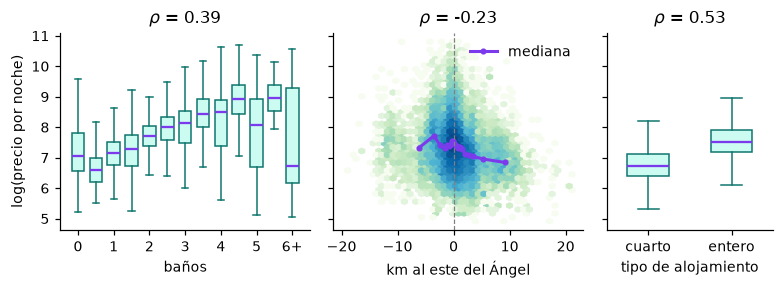

entero
cuarto     840.635
entero    1826.900
Name: precio mediano, dtype: float64


In [6]:
fig, ejes = plt.subplots(1, 3, figsize=(7.2, 2.7), sharey=True,
                         gridspec_kw={"width_ratios": [1.2, 1.2, 0.8]})
y = muestra["log_precio"]

# Banos: caja por numero de banos, con 6 o mas en una sola clase
clase = muestra["banos"].clip(upper=6)
niveles = sorted(clase.unique())
ejes[0].boxplot([y[clase == v] for v in niveles], positions=niveles,
                widths=0.35, showfliers=False, patch_artist=True,
                boxprops={"facecolor": "#ccfbf1", "color": VERDE},
                medianprops={"color": MORADO, "lw": 1.5},
                whiskerprops={"color": VERDE}, capprops={"color": VERDE})
ejes[0].set_xticks([0, 1, 2, 3, 4, 5, 6], ["0", "1", "2", "3", "4", "5",
                                           "6+"])
ejes[0].set_xlabel("baños")
ejes[0].set_ylabel("log(precio por noche)")

ejes[1].hexbin(muestra["este_km"], y, gridsize=40, bins="log",
               cmap="GnBu", mincnt=1)
tendencia = muestra.groupby(pd.qcut(muestra["este_km"], 20),
                            observed=True).agg(x=("este_km", "median"),
                                               y=("log_precio", "median"))
ejes[1].plot(tendencia["x"], tendencia["y"], color=MORADO, lw=2,
             marker="o", ms=3, label="mediana")
ejes[1].axvline(0, color="gray", lw=0.8, ls="--")
ejes[1].set_xlabel("km al este del Ángel")
ejes[1].legend(frameon=False, loc="upper right")

ejes[2].boxplot([y[muestra["entero"] == 0], y[muestra["entero"] == 1]],
                widths=0.5, showfliers=False, patch_artist=True,
                boxprops={"facecolor": "#ccfbf1", "color": VERDE},
                medianprops={"color": MORADO, "lw": 1.5},
                whiskerprops={"color": VERDE}, capprops={"color": VERDE})
ejes[2].set_xticks([1, 2], ["cuarto", "entero"])
ejes[2].set_xlabel("tipo de alojamiento")
for eje, columna in zip(ejes, PREDICTORES):
    rho = stats.spearmanr(muestra[columna], y).statistic
    eje.set_title(rf"$\rho$ = {rho:.2f}")
fig.tight_layout()
fig.savefig(RUTA_FIGURAS / "Dispersion.pdf", bbox_inches="tight")
plt.show()

print(muestra.groupby("entero")["precio"].median()
      .rename({0: "cuarto", 1: "entero"}).rename("precio mediano"))

El precio crece con el número de baños hasta cerca de cinco y se vuelve irregular a partir de seis, donde se concentran hostales con baños compartidos. En la dirección este-oeste el precio alcanza su máximo cerca del centro y del poniente inmediato, y desciende hacia el oriente. El alojamiento entero duplica aproximadamente el precio mediano de un cuarto.

## Pasos 4 y 5: especificación, residuos y ajuste

Se ajusta por mínimos cuadrados ordinarios. Además del error estándar clásico se calcula el robusto agrupado por anfitrión, ya que los anuncios de un mismo anfitrión no son independientes. La prueba de Breusch-Pagan contrasta la hipótesis de varianza constante.

### Modelo 0: precio en pesos

In [7]:
def ajustar(datos, columnas, respuesta):
    """
    Ajusta un modelo lineal por minimos cuadrados ordinarios.
    Ademas del error estandar clasico calcula el robusto agrupado por
    anfitrion (CR1), que no supone independencia entre los anuncios
    de un mismo anfitrion ni varianza constante. Los valores p y los
    intervalos usan el agrupado

    Inputs:
    -------
    datos: DataFrame con las columnas, la respuesta y host_id
    columnas: Lista de columnas que entran como predictores
    respuesta: Nombre de la columna respuesta

    Returns:
    -------
    dict: Tabla de coeficientes, residuos, ajustados y medidas de ajuste

    """
    X = np.column_stack([np.ones(len(datos)), datos[columnas]])
    y = datos[respuesta].to_numpy()
    n, k = X.shape
    xtx_inv = np.linalg.inv(X.T @ X)
    beta = xtx_inv @ X.T @ y
    ajustados = X @ beta
    residuos = y - ajustados

    s2 = residuos @ residuos / (n - k)
    se_clasico = np.sqrt(np.diag(s2 * xtx_inv))

    grupos = datos["host_id"].to_numpy()
    puntaje = pd.DataFrame(X * residuos[:, None]).groupby(grupos).sum()
    medio = puntaje.to_numpy().T @ puntaje.to_numpy()
    g = len(puntaje)
    correccion = g / (g - 1) * (n - 1) / (n - k)
    se = np.sqrt(np.diag(correccion * xtx_inv @ medio @ xtx_inv))
    t = beta / se
    p = 2 * stats.t.sf(np.abs(t), df=g - 1)
    critico = stats.t.ppf(0.975, df=g - 1)

    scr = residuos @ residuos
    r2 = 1 - scr / np.sum((y - y.mean()) ** 2)

    # Breusch-Pagan, version de Koenker
    u = residuos ** 2
    gamma = np.linalg.lstsq(X, u, rcond=None)[0]
    r2_u = 1 - np.sum((u - X @ gamma) ** 2) / np.sum((u - u.mean()) ** 2)
    bp = n * r2_u

    tabla = pd.DataFrame({
        "beta": beta, "EE clasico": se_clasico, "EE agrupado": se,
        "t": t, "p": p,
        "IC 95% inf": beta - critico * se,
        "IC 95% sup": beta + critico * se,
    }, index=["intercepto"] + list(columnas))
    medidas = {"n": n, "anfitriones": g, "R2": r2,
               "R2 ajustada": 1 - (1 - r2) * (n - 1) / (n - k),
               "RMSE": np.sqrt(scr / n),
               "asimetria res.": stats.skew(residuos),
               "curtosis res.": stats.kurtosis(residuos),
               "Breusch-Pagan": bp, "p BP": stats.chi2.sf(bp, k - 1)}
    return {"tabla": tabla, "medidas": medidas, "residuos": residuos,
            "ajustados": ajustados, "beta": beta}


def mostrar(modelo):
    """
    Muestra la tabla de coeficientes y las medidas de ajuste.

    Inputs:
    -------
    modelo: Lo que devuelve ajustar

    Returns:
    -------
    None

    """
    display(modelo["tabla"].round(4))
    display(pd.Series(modelo["medidas"]).to_frame("valor").T.round(4))


m0 = ajustar(muestra, ["banos", "este_km", "entero"], "precio")
mostrar(m0)

,beta,EE clasico,EE agrupado,t,p,IC 95% inf,IC 95% sup
intercepto,140.4706,30.4959,153.1473,0.9172,0.359,-159.7223,440.6636
banos,865.2547,13.7622,128.2380,6.7473,0.000,613.8879,1116.6216
este_km,-60.5638,4.0178,6.9752,-8.6827,0.000,-74.2364,-46.8912
entero,1097.8824,29.6220,66.8740,16.4172,0.000,966.7987,1228.9661


,n,anfitriones,R2,R2 ajustada,RMSE,asimetria res.,curtosis res.,Breusch-Pagan,p BP
valor,28289.0,12205.0,0.1814,0.1813,2329.6352,7.1023,93.8378,1123.6797,0.0


El ajuste es pobre ($R^2 = 0.18$) y los residuos presentan asimetría y curtosis extremas.

### Modelo 1: logaritmo del precio

In [8]:
m1 = ajustar(muestra, ["banos", "este_km", "entero"], "log_precio")
mostrar(m1)

,beta,EE clasico,EE agrupado,t,p,IC 95% inf,IC 95% sup
intercepto,6.6087,0.0079,0.0403,163.9407,0.0,6.5296,6.6877
banos,0.1796,0.0036,0.0331,5.4348,0.0,0.1148,0.2444
este_km,-0.0326,0.0010,0.0025,-13.1484,0.0,-0.0375,-0.0278
entero,0.7148,0.0077,0.0245,29.1176,0.0,0.6667,0.7630


,n,anfitriones,R2,R2 ajustada,RMSE,asimetria res.,curtosis res.,Breusch-Pagan,p BP
valor,28289.0,12205.0,0.3275,0.3274,0.6051,0.4558,3.9842,4158.2637,0.0


### Residuos por clase de predictor

In [9]:
def residuo_por_clase(datos, residuos, grupo):
    """
    Residuo medio y numero de anuncios en cada clase de un agrupador.
    Si el modelo captura la forma de la relacion, el residuo medio se
    queda cerca de cero en todas las clases

    Inputs:
    -------
    datos: DataFrame de los anuncios
    residuos: Arreglo de residuos, en el orden de datos
    grupo: Serie con la clase de cada anuncio

    Returns:
    -------
    DataFrame: Residuo medio y numero de anuncios por clase

    """
    return (pd.Series(residuos, index=datos.index)
            .groupby(grupo, observed=True)
            .agg(["mean", "count"])
            .rename(columns={"mean": "residuo medio", "count": "anuncios"})
            .round(3).T)


CLASES_ESTE = [-30, -10, -6, -4, -2, 0, 2, 4, 6, 10, 30]


def revisar(modelo):
    """
    Residuo medio por numero de banos, por franja este-oeste y por
    tipo de bano.

    Inputs:
    -------
    modelo: Lo que devuelve ajustar

    Returns:
    -------
    None

    """
    res = modelo["residuos"]
    print("por numero de banos")
    display(residuo_por_clase(muestra, res, muestra["banos"].clip(upper=6)))
    print("por km al este del Angel")
    display(residuo_por_clase(muestra, res,
                              pd.cut(muestra["este_km"], CLASES_ESTE)))
    print("por tipo de bano (1 = compartido)")
    display(residuo_por_clase(muestra, res, muestra["compartido"]))
    print("por numero de banos, separado por tipo de bano")
    display(pd.Series(res, index=muestra.index)
            .groupby([muestra["compartido"],
                      muestra["banos"].clip(upper=6)])
            .mean().unstack(0).rename(columns={0: "privado",
                                               1: "compartido"})
            .round(3).T)


revisar(m1)

por numero de banos


banos,0.0,0.5,1.0,1.5,2.0,2.5,3.0,3.5,4.0,4.5,5.0,5.5,6.0
residuo medio,0.333,0.018,-0.053,-0.018,0.092,0.227,0.273,0.454,0.335,0.723,-0.091,0.682,-0.718
anuncios,186.000,133.000,18661.000,1686.000,4994.000,918.000,659.000,311.000,223.000,110.000,82.000,38.000,288.000


por km al este del Angel


este_km,"(-30, -10]","(-10, -6]","(-6, -4]","(-4, -2]","(-2, 0]","(0, 2]","(2, 4]","(4, 6]","(6, 10]","(10, 30]"
residuo medio,-0.334,-0.331,-0.119,0.051,0.068,0.026,-0.118,-0.126,-0.005,-0.076
anuncios,366.000,389.000,763.000,2798.000,8402.000,9024.000,3747.000,926.000,1408.000,466.000


por tipo de bano (1 = compartido)


compartido,0,1
residuo medio,0.043,-0.272
anuncios,24457.000,3832.000


por numero de banos, separado por tipo de bano


banos,0.0,0.5,1.0,1.5,2.0,2.5,3.0,3.5,4.0,4.5,5.0,5.5,6.0
compartido,,,,,,,,,,,,,
privado,0.298,0.052,-0.034,0.066,0.13,0.305,0.390,0.593,0.671,0.813,0.394,0.682,0.042
compartido,0.356,-0.024,-0.174,-0.306,-0.39,-0.416,-0.441,-0.719,-0.743,-1.161,-1.028,NaN,-1.604


El residuo por número de baños es negativo en el grupo de seis o más y positivo entre 2.5 y 4.5: los anuncios con muchos baños compartidos aplanan la pendiente. Se sustituye el número de baños por $\log(1 + \text{baños})$, que reduce la influencia de esos valores extremos.

### Modelo 2

In [10]:
muestra["log_banos"] = np.log1p(muestra["banos"])
FINALES = ["log_banos", "este_km", "entero"]
m2 = ajustar(muestra, FINALES, "log_precio")
mostrar(m2)
revisar(m2)

,beta,EE clasico,EE agrupado,t,p,IC 95% inf,IC 95% sup
intercepto,6.2523,0.0119,0.0541,115.4959,0.0,6.1462,6.3584
log_banos,0.7519,0.0128,0.0763,9.8508,0.0,0.6023,0.9015
este_km,-0.0310,0.0010,0.0025,-12.3436,0.0,-0.0359,-0.0261
entero,0.6836,0.0076,0.0253,27.0692,0.0,0.6341,0.7330


,n,anfitriones,R2,R2 ajustada,RMSE,asimetria res.,curtosis res.,Breusch-Pagan,p BP
valor,28289.0,12205.0,0.3468,0.3467,0.5963,0.6028,2.9622,1583.6794,0.0


por numero de banos


banos,0.0,0.5,1.0,1.5,2.0,2.5,3.0,3.5,4.0,4.5,5.0,5.5,6.0
residuo medio,0.7,0.161,-0.02,-0.065,0.009,0.118,0.15,0.337,0.222,0.636,-0.166,0.651,-0.547
anuncios,186.0,133.000,18661.00,1686.000,4994.000,918.000,659.00,311.000,223.000,110.000,82.000,38.000,288.000


por km al este del Angel


este_km,"(-30, -10]","(-10, -6]","(-6, -4]","(-4, -2]","(-2, 0]","(0, 2]","(2, 4]","(4, 6]","(6, 10]","(10, 30]"
residuo medio,-0.32,-0.323,-0.123,0.05,0.067,0.024,-0.112,-0.131,-0.0,-0.086
anuncios,366.00,389.000,763.000,2798.00,8402.000,9024.000,3747.000,926.000,1408.0,466.000


por tipo de bano (1 = compartido)


compartido,0,1
residuo medio,0.043,-0.276
anuncios,24457.000,3832.000


por numero de banos, separado por tipo de bano


banos,0.0,0.5,1.0,1.5,2.0,2.5,3.0,3.5,4.0,4.5,5.0,5.5,6.0
compartido,,,,,,,,,,,,,
privado,0.683,0.198,0.002,0.025,0.049,0.200,0.272,0.479,0.565,0.728,0.330,0.651,0.266
compartido,0.711,0.116,-0.161,-0.372,-0.503,-0.553,-0.592,-0.865,-0.878,-1.279,-1.123,NaN,-1.494


La transformación mejora el ajuste, pero el patrón por número de baños persiste. La tabla separada por tipo de baño explica la causa: con baño privado, el residuo crece con el número de baños; con baño compartido, decrece. El número de baños mezcla dos poblaciones con pendientes opuestas. En la dirección este-oeste, los anuncios a más de 6 km al poniente (Cuajimalpa y Álvaro Obregón) son más baratos de lo que predice el término lineal.

### Variantes y comparación

In [11]:
muestra["este_km2"] = muestra["este_km"] ** 2
VARIANTES = {
    "modelo 2": FINALES,
    "modelo 2 + este^2": FINALES + ["este_km2"],
    "modelo 2 + bano compartido": FINALES + ["compartido"],
}
display(pd.Series({nombre: ajustar(muestra, columnas, "log_precio")
                   ["medidas"]["R2"]
                   for nombre, columnas in VARIANTES.items()},
                  name="R2").round(4).to_frame())

comparacion = pd.DataFrame({
    "Modelo 0: precio": m0["medidas"],
    "Modelo 1: log(precio)": m1["medidas"],
    "Modelo 2: log(1 + banos)": m2["medidas"],
}).T
display(comparacion[["R2", "R2 ajustada", "RMSE", "asimetria res.",
                     "curtosis res.", "Breusch-Pagan"]].round(4))

,R2
modelo 2,0.3468
modelo 2 + este^2,0.3516
modelo 2 + bano compartido,0.3793


,R2,R2 ajustada,RMSE,asimetria res.,curtosis res.,Breusch-Pagan
Modelo 0: precio,0.1814,0.1813,2329.6352,7.1023,93.8378,1123.6797
Modelo 1: log(precio),0.3275,0.3274,0.6051,0.4558,3.9842,4158.2637
Modelo 2: log(1 + banos),0.3468,0.3467,0.5963,0.6028,2.9622,1583.6794


Un término cuadrático en la posición este-oeste aporta menos de una centésima de $R^2$ y no se incluye. La indicadora de baño compartido aportaría más, pero sería una cuarta variable correlacionada con el tipo de alojamiento; se reporta como limitación.

### Diagnóstico del modelo final

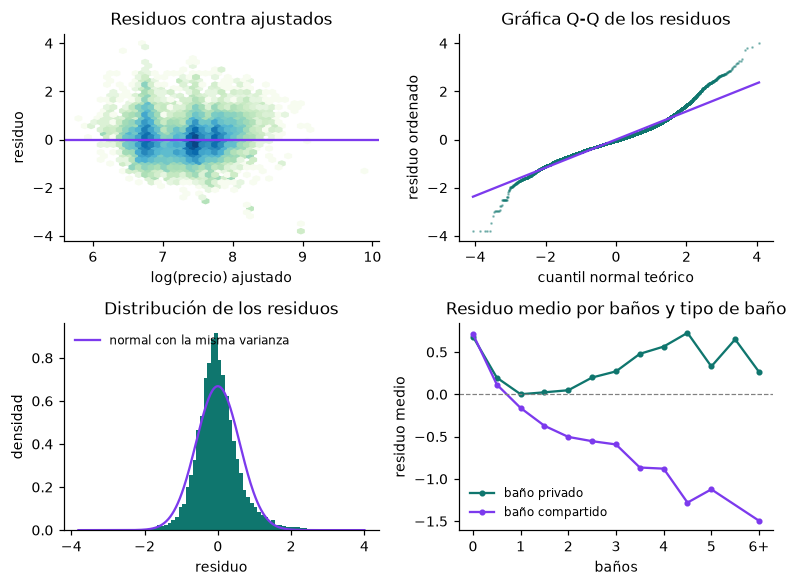

desviacion estandar del residuo


,por tipo de alojamiento,por tipo de bano
compartido,NaN,0.675
cuarto,0.714,NaN
entero,0.529,NaN
privado,NaN,0.571


In [12]:
fig, ejes = plt.subplots(2, 2, figsize=(7.2, 5.4))
res, aj = m2["residuos"], m2["ajustados"]

ejes[0, 0].hexbin(aj, res, gridsize=45, bins="log", cmap="GnBu", mincnt=1)
ejes[0, 0].axhline(0, color=MORADO, lw=1.5)
ejes[0, 0].set(xlabel="log(precio) ajustado", ylabel="residuo",
               title="Residuos contra ajustados")

(teoricos, ordenados), (pendiente, corte, _) = stats.probplot(res)
ejes[0, 1].plot(teoricos, ordenados, ".", color=VERDE, ms=1.5, alpha=0.4)
ejes[0, 1].plot(teoricos, pendiente * teoricos + corte, color=MORADO,
                lw=1.5)
ejes[0, 1].set(xlabel="cuantil normal teórico", ylabel="residuo ordenado",
               title="Gráfica Q-Q de los residuos")

ejes[1, 0].hist(res, bins=80, color=VERDE, density=True)
malla = np.linspace(res.min(), res.max(), 300)
ejes[1, 0].plot(malla, stats.norm.pdf(malla, 0, res.std()), color=MORADO,
                lw=1.5, label="normal con la misma varianza")
ejes[1, 0].set(xlabel="residuo", ylabel="densidad",
               title="Distribución de los residuos")
ejes[1, 0].legend(frameon=False, fontsize=8, loc="upper left")

# Residuo medio por numero de banos, separado por tipo de bano: las
# dos poblaciones que el modelo promedia
clase = muestra["banos"].clip(upper=6)
for valor, nombre, color in [(0, "privado", VERDE),
                             (1, "compartido", MORADO)]:
    filtro = (muestra["compartido"] == valor).to_numpy()
    medio = pd.Series(res[filtro]).groupby(clase[filtro].to_numpy()).mean()
    ejes[1, 1].plot(medio.index, medio.values, marker="o", ms=3, lw=1.5,
                    color=color, label=f"baño {nombre}")
ejes[1, 1].axhline(0, color="gray", lw=0.8, ls="--")
ejes[1, 1].set_xticks([0, 1, 2, 3, 4, 5, 6], ["0", "1", "2", "3", "4", "5",
                                              "6+"])
ejes[1, 1].set(xlabel="baños", ylabel="residuo medio",
               title="Residuo medio por baños y tipo de baño")
ejes[1, 1].legend(frameon=False, fontsize=8, loc="lower left")
fig.tight_layout()
fig.savefig(RUTA_FIGURAS / "Diagnostico.pdf", bbox_inches="tight")
plt.show()

serie = pd.Series(res, index=muestra.index)
print("desviacion estandar del residuo")
display(pd.DataFrame({
    "por tipo de alojamiento": serie.groupby(muestra["entero"]).std()
    .rename({0: "cuarto", 1: "entero"}),
    "por tipo de bano": serie.groupby(muestra["compartido"]).std()
    .rename({0: "privado", 1: "compartido"}),
}).round(3))

### Validación en una partición de prueba

In [13]:
generador = np.random.default_rng(SEMILLA)
en_prueba = generador.random(len(muestra)) < 0.2
entrena, prueba = muestra[~en_prueba], muestra[en_prueba]
m2_entrena = ajustar(entrena, FINALES, "log_precio")

X_prueba = np.column_stack([np.ones(len(prueba)), prueba[FINALES]])
predicho = X_prueba @ m2_entrena["beta"]
real = prueba["log_precio"].to_numpy()
r2_prueba = 1 - np.sum((real - predicho) ** 2) / np.sum(
    (real - real.mean()) ** 2)
pesos_real, pesos_pred = np.exp(real), np.exp(predicho)
display(pd.DataFrame({
    "entrenamiento": {"anuncios": len(entrena),
                      "R2": m2_entrena["medidas"]["R2"],
                      "RMSE log": m2_entrena["medidas"]["RMSE"]},
    "prueba": {"anuncios": len(prueba), "R2": r2_prueba,
               "RMSE log": np.sqrt(np.mean((real - predicho) ** 2))},
}).T.round(4))
print(f"error absoluto mediano en prueba: "
      f"{np.median(np.abs(pesos_real - pesos_pred)):,.0f} pesos")
print(f"error porcentual absoluto mediano en prueba: "
      f"{np.median(np.abs(pesos_real - pesos_pred) / pesos_real) * 100:.1f} %")
display(m2_entrena["tabla"][["beta"]].T.round(4))

,anuncios,R2,RMSE log
entrenamiento,22673.0,0.3477,0.5974
prueba,5616.0,0.3431,0.5920


error absoluto mediano en prueba: 449 pesos
error porcentual absoluto mediano en prueba: 32.1 %


,intercepto,log_banos,este_km,entero
beta,6.2516,0.7537,-0.0318,0.6832


## Interpretación de los coeficientes

In [14]:
b = m2["tabla"]["beta"]
efectos = pd.DataFrame({
    "cambio": ["de 1 a 2 baños", "de 1 a 3 baños", "1 km más al este",
               "5 km más al este", "cuarto a alojamiento entero"],
    "efecto en el precio (%)": [
        ((3 / 2) ** b["log_banos"] - 1) * 100,
        ((4 / 2) ** b["log_banos"] - 1) * 100,
        (np.exp(b["este_km"]) - 1) * 100,
        (np.exp(5 * b["este_km"]) - 1) * 100,
        (np.exp(b["entero"]) - 1) * 100,
    ],
})
display(efectos.round(1))

,cambio,efecto en el precio (%)
0,de 1 a 2 baños,35.6
1,de 1 a 3 baños,68.4
2,1 km más al este,-3.1
3,5 km más al este,-14.4
4,cuarto a alojamiento entero,98.1


## Resultado

$$\widehat{\log(\text{precio})} = 6.252 + 0.752\,\log(1 + \text{baños}) - 0.031\,\text{este} + 0.684\,\text{entero}$$

con $R^2 = 0.347$ sobre 28,289 anuncios de 12,205 anfitriones.